In [ ]:
from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

nights = [
    "20260731",
    "20260702",
    "20260822",
    "20260719",
    "20260805",
    "20260714",
    "20260823",
    "20260819",
    "20260715",
    "20260803",
]

for night in nights:
    columns_headers = {"image_name": [], "wppos": [], "wpang": [], "error": []}
    images_folder = Path(f"E:/images/{night}")
    images = list(images_folder.glob("*.fits"))
    headers = [fits.getheader(image) for image in images]

    for header in headers:
        if header["INSTMODE"] != "POLAR":
            continue
        if header["OBSTYPE"] not in ["OBJECT", "FLAT"]:
            continue
        if header["WPANG"] == "":
            continue
        columns_headers["image_name"].append(header["FILENAME"])
        columns_headers["wppos"].append(header["WPPOS"])
        columns_headers["wpang"].append(header["WPANG"])

    for idx, (wppos, wpang) in enumerate(
        zip(columns_headers["wppos"], columns_headers["wpang"])
    ):
        expected_ang = 22.5 * (wppos - 1)
        error = expected_ang - wpang
        columns_headers["error"].append(error)

    df = pd.DataFrame.from_dict(columns_headers)
    df = df[-300 < df["error"]]
    csv_file = Path.cwd() / "_csv" / f"{night}.csv"
    df.to_csv(csv_file)

20260731 & 5.45 & 6.00\\
20260702 & -124.11 & 147.64\\
20260822 & -0.50 & 2.69\\
20260719 & 1.02 & 4.90\\
20260805 & 0.10 & 1.06\\
20260714 & -7.28 & 10.79\\
20260823 & 3.56 & 7.36\\
20260819 & 0.04 & 0.73\\
20260715 & 0.64 & 2.87\\
20260803 & -0.24 & 5.03\\


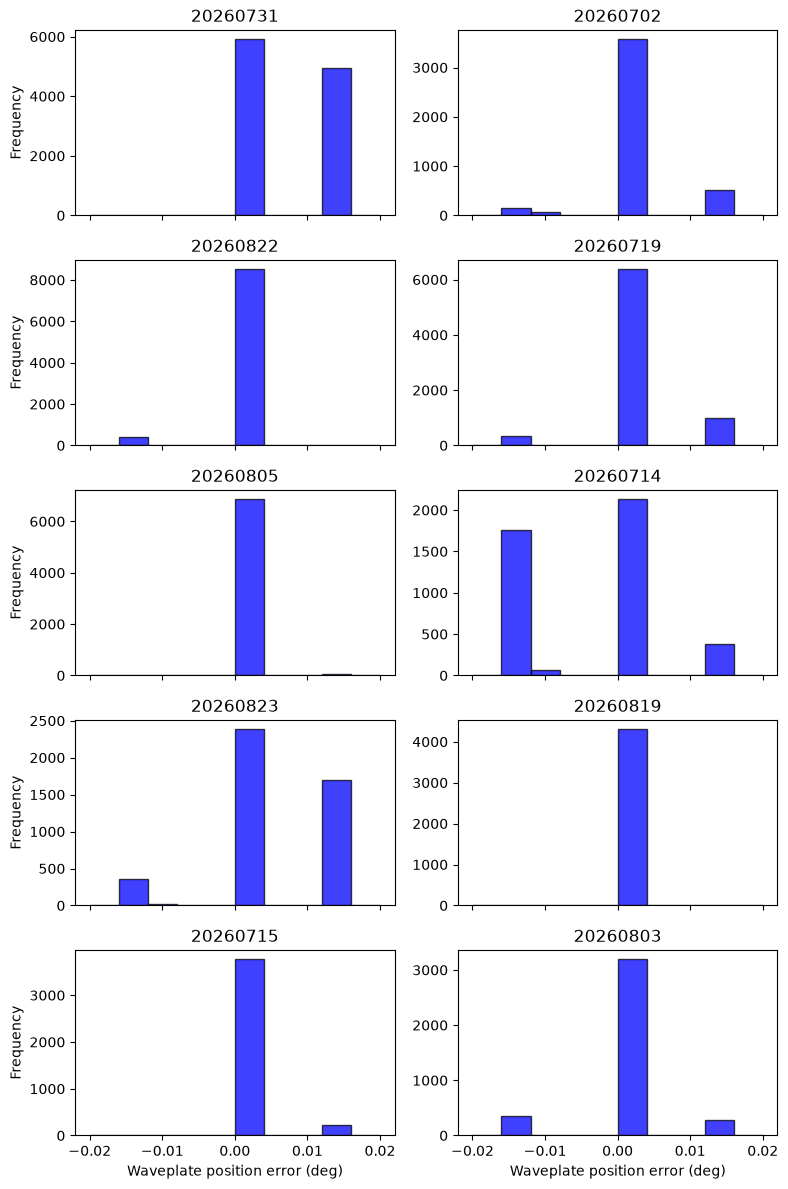

In [14]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path

fig, axs = plt.subplots(5, 2, sharex=True, figsize=(8, 12))
axs = axs.flatten()


nights = [
    "20260731",
    "20260702",
    "20260822",
    "20260719",
    "20260805",
    "20260714",
    "20260823",
    "20260819",
    "20260715",
    "20260803",
]
for idx, night in enumerate(nights):
    ax = axs[idx]
    csv_file = Path.cwd() / "_csv" / f"{night}.csv"
    df = pd.read_csv(csv_file)
    mean = np.mean(df["error"]) * 1e3
    std = np.std(df["error"]) * 1e3
    ax.hist(
        df["error"], color="blue", edgecolor="black", alpha=0.75, range=(-0.02, 0.02)
    )
    ax.set_title(rf"{night}")
    if idx % 2 == 0:
        ax.set_ylabel("Frequency")
    print(
        rf"{night} & {mean:.2f} & {std:.2f}\\",
    )


axs[-1].set_xlabel("Waveplate position error (deg)")
axs[-2].set_xlabel("Waveplate position error (deg)")
plt.tight_layout()
image_path = Path.cwd() / "_figs" / "wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(r"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\error_histograms.png")
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
4 % 2

0